<a href="https://colab.research.google.com/github/Munana122/hmm-activity/blob/main/hmm_states.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, re, glob, zipfile, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment
from scipy.signal import butter, sosfiltfilt

warnings.filterwarnings("ignore")
RNG = np.random.default_rng(42)

ACTIVITIES = ["standing", "walking", "jumping", "still"]
K = len(ACTIVITIES)

TARGET_FS = 50
WIN_SEC   = 2.0
OVERLAP   = 0.5
TRIM_SEC  = 0.5
NFFT      = 256
WIN  = int(WIN_SEC * TARGET_FS)
STEP = int(WIN * (1 - OVERLAP))
os.makedirs("figures", exist_ok=True)
print(f"Window = {WIN} samples ({WIN_SEC}s), step = {STEP} samples, FFT resolution = {TARGET_FS/NFFT:.2f} Hz")

Window = 100 samples (2.0s), step = 50 samples, FFT resolution = 0.20 Hz


In [4]:
DATA_SOURCE = "sensorlogger"
N_TEST = 3
PERSON = "p1"
GITHUB_URL  = "https://github.com/Munana122/hmm-activity.git"
DRIVE_BASE  = "/content/drive/MyDrive/hmm_activity"

SL_RE = re.compile(r"^(standing|walking|jumping|still)[-_ ](\d{4}-\d{2}-\d{2})[_ -](\d{2}-\d{2}-\d{2})", re.I)

def import_sensor_logger_zips(zip_paths, raw_dir, person, n_test):
    """Unzip Sensor Logger exports named like Walking-2026-10-28_13-45-17.zip and rename them
    chronologically to raw/<activity>_<person>_<NN>/ (latest n_test per activity go to raw/test/)."""
    import shutil, tempfile
    items = {a: [] for a in ACTIVITIES}
    for z in zip_paths:
        m = SL_RE.match(os.path.basename(z))
        if not m or not z.lower().endswith(".zip"):
            print("skip (not a recognised Sensor Logger zip):", z); continue
        items[m.group(1).lower()].append((m.group(2) + m.group(3), z))
    for a, lst in items.items():
        lst.sort()
        n_train = len(lst) - n_test
        for i, (_, z) in enumerate(lst):
            is_test = i >= n_train
            idx = i - n_train + 1 if is_test else i + 1
            dest = os.path.join(raw_dir, "test" if is_test else "", f"{a}_{person}_{idx:02d}")
            tmp = tempfile.mkdtemp(); zipfile.ZipFile(z).extractall(tmp)
            found = {f: os.path.join(r, f) for r, _, fs in os.walk(tmp) for f in fs if f in ("Accelerometer.csv", "Gyroscope.csv")}
            if len(found) < 2:
                print("skip (needs Accelerometer.csv and Gyroscope.csv inside):", z); continue
            os.makedirs(dest, exist_ok=True)
            for f, p in found.items(): shutil.copy(p, os.path.join(dest, f))
        print(f"{a:9s}: {len(lst) - n_test if len(lst) > n_test else 0} train, {min(n_test, len(lst))} test")

DATA_DIR, RAW_DIR = "data", "raw"
import shutil
shutil.rmtree(RAW_DIR, ignore_errors=True); shutil.rmtree(DATA_DIR, ignore_errors=True)
if DATA_SOURCE == "sensorlogger":
    from google.colab import files
    print("Select ALL your Sensor Logger .zip files (Ctrl+A in the file dialog)")
    import_sensor_logger_zips(list(files.upload()), RAW_DIR, PERSON, N_TEST)
elif DATA_SOURCE == "upload":
    from google.colab import files
    print("Select data.zip (contains the folder data/, and optionally raw/)")
    for name in files.upload():
        if name.lower().endswith(".zip"):
            zipfile.ZipFile(name).extractall(".")
elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR, RAW_DIR = f"{DRIVE_BASE}/data", f"{DRIVE_BASE}/raw"
elif DATA_SOURCE == "github":
    subprocess.run(["git", "clone", GITHUB_URL, "repo"], check=False)
    DATA_DIR, RAW_DIR = "repo/data", "repo/raw"
print("DATA_DIR =", DATA_DIR, "| exists:", os.path.isdir(DATA_DIR))

Select ALL your Sensor Logger .zip files (Ctrl+A in the file dialog)


Saving still-2026-11-01_18-02-19.zip to still-2026-11-01_18-02-19.zip
Saving still-2026-11-01_18-02-31.zip to still-2026-11-01_18-02-31.zip
Saving Standing-2026-11-01_17-51-59.zip to Standing-2026-11-01_17-51-59.zip
Saving Standing-2026-11-01_17-52-16.zip to Standing-2026-11-01_17-52-16.zip
Saving Standing-2026-11-01_17-52-29.zip to Standing-2026-11-01_17-52-29.zip
Saving Walking-2026-11-01_17-53-19.zip to Walking-2026-11-01_17-53-19.zip
Saving Walking-2026-11-01_17-58-55.zip to Walking-2026-11-01_17-58-55.zip
Saving Walking-2026-11-01_17-58-42.zip to Walking-2026-11-01_17-58-42.zip
Saving Jumping-2026-11-01_17-59-36.zip to Jumping-2026-11-01_17-59-36.zip
Saving Jumping-2026-11-01_17-59-20.zip to Jumping-2026-11-01_17-59-20.zip
Saving Jumping-2026-11-01_17-59-58.zip to Jumping-2026-11-01_17-59-58.zip
Saving still-2026-11-01_18-02-52.zip to still-2026-11-01_18-02-52.zip
Saving still-2026-10-29_10-04-08.zip to still-2026-10-29_10-04-08.zip
Saving still-2026-10-29_10-04-19.zip to still-20

In [5]:
def merge_sensor_logger(raw_dir, out_dir):
    n = 0
    for root, _, fs in os.walk(raw_dir):
        if "Accelerometer.csv" in fs and "Gyroscope.csv" in fs:
            acc = pd.read_csv(os.path.join(root, "Accelerometer.csv"))
            gyr = pd.read_csv(os.path.join(root, "Gyroscope.csv"))
            t = acc["seconds_elapsed"].values
            out = pd.DataFrame({"timestamp": t, "ax": acc["x"], "ay": acc["y"], "az": acc["z"]})
            for c in "xyz":
                out["g" + c] = np.interp(t, gyr["seconds_elapsed"].values, gyr[c].values)
            dest = os.path.join(out_dir, os.path.relpath(root, raw_dir) + ".csv")
            os.makedirs(os.path.dirname(dest), exist_ok=True)
            out.to_csv(dest, index=False); n += 1
    print(f"merged {n} recordings -> {out_dir}")

if os.path.isdir(RAW_DIR):
    merge_sensor_logger(RAW_DIR, DATA_DIR)
else:
    print("No raw/ folder found - using the CSV files already in", DATA_DIR)


merged 64 recordings -> data


In [6]:
FILE_RE = re.compile(r"^(standing|walking|jumping|still)_(p\d+)_(\d+)\.csv$", re.I)
AXES = ["ax", "ay", "az", "gx", "gy", "gz"]

def _to_seconds(t):
    m = np.nanmax(np.abs(t))
    if m > 1e17: return t / 1e9
    if m > 1e11: return t / 1e3
    return t

def read_recording(path):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    tcol = next((c for c in ("timestamp", "time", "seconds_elapsed") if c in df.columns), None)
    if tcol is None: raise ValueError("no timestamp column")
    miss = [a for a in AXES if a not in df.columns]
    if miss: raise ValueError(f"missing columns {miss}")
    df = df[[tcol] + AXES].dropna().sort_values(tcol).drop_duplicates(tcol)
    t = _to_seconds(df[tcol].astype(float).values); t = t - t[0]
    X = df[AXES].astype(float).values
    dt = np.diff(t)
    native_fs = 1.0 / np.median(dt)
    max_gap = dt.max()
    if native_fs > TARGET_FS * 1.05:
        sos = butter(4, 0.45 * TARGET_FS, btype="low", fs=native_fs, output="sos")
        X = sosfiltfilt(sos, X, axis=0)
    grid = np.arange(0, t[-1], 1 / TARGET_FS)
    Xr = np.column_stack([np.interp(grid, t, X[:, j]) for j in range(6)])
    n_trim = int(TRIM_SEC * TARGET_FS)
    return Xr[n_trim: len(Xr) - n_trim], native_fs, t[-1], max_gap

def load_folder(folder, split):
    recs = []
    for p in sorted(glob.glob(os.path.join(folder, "*.csv"))):
        name = os.path.basename(p)
        m = FILE_RE.match(name)
        if not m:
            print("skip (name does not match <activity>_<person>_<NN>.csv):", name); continue
        try:
            sig, fs, dur, gap = read_recording(p)
        except Exception as e:
            print("skip", name, "->", e); continue
        if len(sig) < WIN:
            print("skip (too short):", name); continue
        recs.append(dict(file=name, activity=m.group(1).lower(), person=m.group(2).lower(),
                         native_fs=round(fs, 1), duration=round(dur, 2), max_gap=round(gap, 3),
                         sig=sig, split=split))
    return recs

train_recs = load_folder(DATA_DIR, "train")
test_dir = os.path.join(DATA_DIR, "test")
test_recs = load_folder(test_dir, "test") if os.path.isdir(test_dir) else []

if not test_recs:
    print("WARNING: no data/test/ files found. Holding out every 5th file per activity as a TEMPORARY test set.")
    keep = []
    for a in ACTIVITIES:
        rs = [r for r in train_recs if r["activity"] == a]
        for i, r in enumerate(rs):
            if i % 5 == 4: r["split"] = "test"; test_recs.append(r)
            else: keep.append(r)
    train_recs = keep
print(f"train files: {len(train_recs)} | test files: {len(test_recs)}")

train files: 52 | test files: 12


In [7]:
meta = pd.DataFrame([{k: v for k, v in r.items() if k != "sig"} for r in train_recs + test_recs])
meta.to_csv("dataset_inventory.csv", index=False)

summary = meta[meta.split == "train"].groupby("activity").agg(files=("file", "count"), total_seconds=("duration", "sum")).reindex(ACTIVITIES)
display(summary) if "display" in globals() else print(summary)
print("\nSampling rate per person (native, Hz) - put this in the report:")
print(meta.groupby("person").native_fs.agg(["count", "min", "median", "max"]))

print("\nChecks:")
print(f"  >= 50 files in total ........ {'OK' if len(meta) >= 50 else 'NOT YET'} ({len(meta)})")
for a in ACTIVITIES:
    s = summary.loc[a, "total_seconds"]
    print(f"  {a:9s} >= 90 s ......... {'OK' if s >= 90 else 'NOT YET'} ({s:.0f} s)")
bad = meta[meta.max_gap > 0.5]
print(f"  files with timestamp gaps > 0.5 s: {len(bad)}", list(bad.file) if len(bad) else "")


          files  total_seconds
activity                      
standing     13         136.51
walking      13         127.71
jumping      13         116.96
still        13         141.40

Sampling rate per person (native, Hz) - put this in the report:
        count    min  median    max
person                             
p1         64  100.6   100.6  100.7

Checks:
  >= 50 files in total ........ OK (64)
  standing  >= 90 s ......... OK (137 s)
  walking   >= 90 s ......... OK (128 s)
  jumping   >= 90 s ......... OK (117 s)
  still     >= 90 s ......... OK (141 s)
  files with timestamp gaps > 0.5 s: 0 


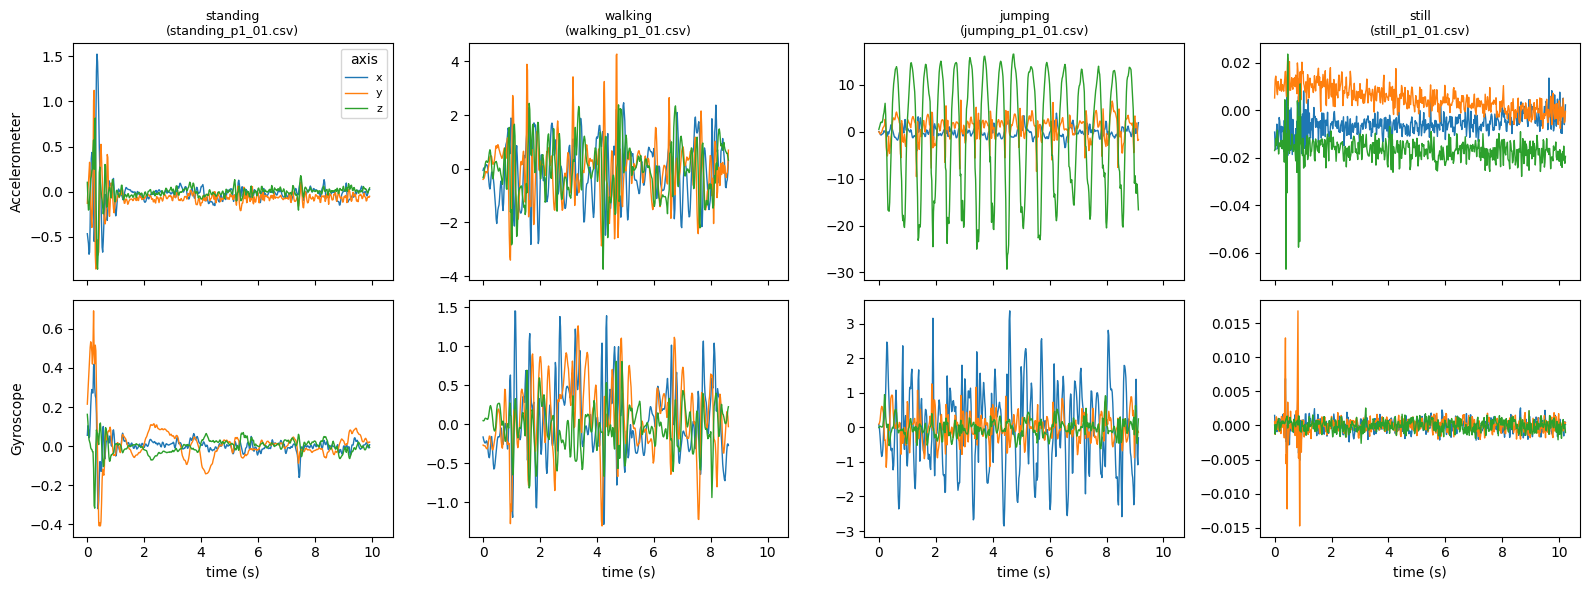

In [8]:
fig, axs = plt.subplots(2, K, figsize=(16, 6), sharex=True)
for j, a in enumerate(ACTIVITIES):
    r = next((r for r in train_recs if r["activity"] == a), None)
    if r is None: continue
    t = np.arange(len(r["sig"])) / TARGET_FS
    for i, c in enumerate("xyz"):
        axs[0, j].plot(t, r["sig"][:, i], lw=1, label=c)
        axs[1, j].plot(t, r["sig"][:, 3 + i], lw=1, label=c)
    axs[0, j].set_title(f"{a}\n({r['file']})", fontsize=9)
axs[0, 0].set_ylabel("Accelerometer"); axs[1, 0].set_ylabel("Gyroscope")
for ax in axs[1]: ax.set_xlabel("time (s)")
axs[0, 0].legend(title="axis", fontsize=8)
plt.tight_layout(); plt.savefig("figures/raw_samples.png", dpi=150); plt.show()

In [9]:
FREQS = np.fft.rfftfreq(NFFT, 1 / TARGET_FS)
FEATURE_NAMES = [f"{s}_{f}" for s in ("acc", "gyr") for f in ("rms", "sma", "ptp", "domfreq", "energy", "entropy")] \
                + ["acc_corr_xy", "acc_corr_xz", "acc_corr_yz"]
LOG_IDX = [i for i, n in enumerate(FEATURE_NAMES) if n.split("_")[1] in ("rms", "sma", "ptp", "energy")]

def power_spectrum(a):
    w = np.hanning(a.shape[0])[:, None]
    P = (np.abs(np.fft.rfft(a * w, n=NFFT, axis=0)) ** 2).sum(1)
    P[0] = 0
    return P

def window_features(w):
    f = []
    for sl in (slice(0, 3), slice(3, 6)):
        a = w[:, sl] - w[:, sl].mean(0)
        rms = np.sqrt((a ** 2).sum(1).mean())
        sma = np.abs(a).sum(1).mean()
        ptp = (a.max(0) - a.min(0)).max()
        P = power_spectrum(a)
        dom = FREQS[np.argmax(P)]
        energy = P.sum() / NFFT
        p = P / (P.sum() + 1e-12)
        ent = -(p * np.log(p + 1e-12)).sum()
        f += [rms, sma, ptp, dom, energy, ent]
    acc = w[:, :3]
    def corr(i, j):
        if acc[:, i].std() < 1e-8 or acc[:, j].std() < 1e-8: return 0.0
        return float(np.corrcoef(acc[:, i], acc[:, j])[0, 1])
    return np.array(f + [corr(0, 1), corr(0, 2), corr(1, 2)])

def featurize(recs):
    for r in recs:
        W = [r["sig"][s:s + WIN] for s in range(0, len(r["sig"]) - WIN + 1, STEP)]
        r["F_raw"] = np.array([window_features(w) for w in W])
        r["y"] = np.full(len(W), ACTIVITIES.index(r["activity"]))

def log_transform(F):
    F = F.copy(); F[:, LOG_IDX] = np.log10(F[:, LOG_IDX] + 1e-6); return F

featurize(train_recs); featurize(test_recs)
Ftr = log_transform(np.vstack([r["F_raw"] for r in train_recs]))
MU, SD = Ftr.mean(0), Ftr.std(0) + 1e-9
for r in train_recs + test_recs:
    r["X"] = (log_transform(r["F_raw"]) - MU) / SD

print("windows -> train:", sum(len(r["y"]) for r in train_recs), "| test:", sum(len(r["y"]) for r in test_recs))
for a in ACTIVITIES:
    print(f"  {a:9s} train windows: {sum(len(r['y']) for r in train_recs if r['activity']==a)}")

windows -> train: 392 | test: 93
  standing  train windows: 103
  walking   train windows: 95
  jumping   train windows: 85
  still     train windows: 109


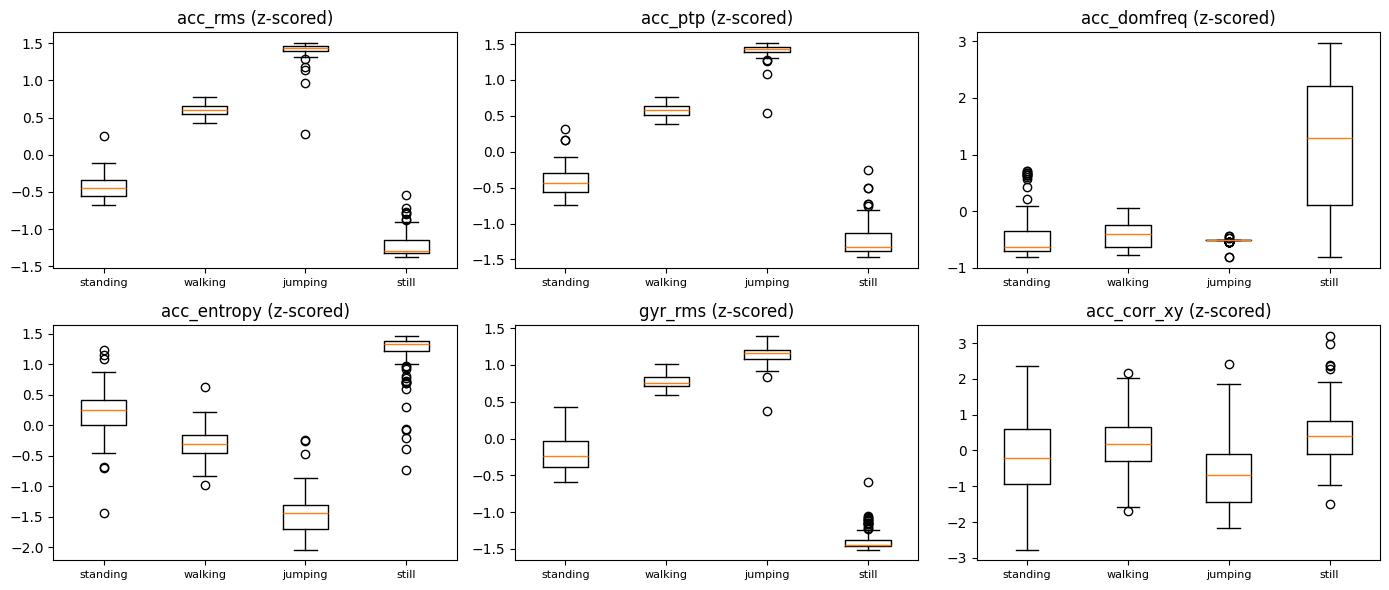

In [10]:
show = ["acc_rms", "acc_ptp", "acc_domfreq", "acc_entropy", "gyr_rms", "acc_corr_xy"]
Xall = np.vstack([r["X"] for r in train_recs]); yall = np.concatenate([r["y"] for r in train_recs])
fig, axs = plt.subplots(2, 3, figsize=(14, 6))
for ax, name in zip(axs.ravel(), show):
    j = FEATURE_NAMES.index(name)
    ax.boxplot([Xall[yall == k, j] for k in range(K)])
    ax.set_xticks(range(1, K + 1)); ax.set_xticklabels(ACTIVITIES, fontsize=8)
    ax.set_title(name + " (z-scored)")
plt.tight_layout(); plt.savefig("figures/feature_boxplots.png", dpi=150); plt.show()

In [11]:
  class GaussianHMM:
    def __init__(self, n_states, n_features, var_floor=1e-2):
        self.K, self.D, self.var_floor = n_states, n_features, var_floor
        self.pi = np.full(K, 1 / K); self.A = np.full((K, K), 1 / K)
        self.mu = np.zeros((K, n_features)); self.var = np.ones((K, n_features))

    @staticmethod
    def _log(x): return np.log(np.clip(x, 1e-300, None))

    def init_from_labels(self, seqs, labels, smooth=1.0):
        Xa, ya = np.vstack(seqs), np.concatenate(labels)
        for k in range(self.K):
            Xk = Xa[ya == k]
            if len(Xk) == 0: raise ValueError(f"no training windows for state {k}")
            self.mu[k], self.var[k] = Xk.mean(0), Xk.var(0) + self.var_floor
        A = np.full((self.K, self.K), smooth); pi = np.full(self.K, smooth)
        for y in labels:
            pi[y[0]] += 1
            for a, b in zip(y[:-1], y[1:]): A[a, b] += 1
        self.A, self.pi = A / A.sum(1, keepdims=True), pi / pi.sum()
        return self

    def log_emission(self, X):                                   # (T, K)
        d = X[:, None, :] - self.mu[None]
        return -0.5 * (np.log(2 * np.pi * self.var).sum(1)[None] + (d ** 2 / self.var[None]).sum(2))

    def _forward(self, logB):
        T = len(logB); logA = self._log(self.A); la = np.zeros((T, self.K))
        la[0] = self._log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        return la, logsumexp(la[-1])

    def _backward(self, logB):
        T = len(logB); logA = self._log(self.A); lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        return lb

    def viterbi(self, X):
        logB, logA = self.log_emission(X), self._log(self.A)
        T = len(X); delta = np.zeros((T, self.K)); psi = np.zeros((T, self.K), int)
        delta[0] = self._log(self.pi) + logB[0]
        for t in range(1, T):
            s = delta[t - 1][:, None] + logA
            psi[t], delta[t] = s.argmax(0), s.max(0) + logB[t]
        path = np.zeros(T, int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1): path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

    def fit(self, seqs, max_iter=200, tol=1e-4, verbose=True):
        hist = []
        for it in range(max_iter):
            logA = self._log(self.A)
            g0 = np.zeros(self.K); xi = np.zeros((self.K, self.K))
            gs = np.zeros(self.K); gx = np.zeros((self.K, self.D)); gxx = np.zeros((self.K, self.D))
            total_ll, n = 0.0, 0
            for X in seqs:                                       # ---- E-step
                logB = self.log_emission(X)
                la, ll = self._forward(logB); lb = self._backward(logB)
                gamma = np.exp(la + lb - ll)
                g0 += gamma[0]
                if len(X) > 1:
                    lxi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll
                    xi += np.exp(lxi).sum(0)
                gs += gamma.sum(0); gx += gamma.T @ X; gxx += gamma.T @ (X ** 2)
                total_ll += ll; n += len(X)
            self.pi = (g0 + 1e-6) / (g0 + 1e-6).sum()            # ---- M-step
            A = xi + 1e-3; self.A = A / A.sum(1, keepdims=True)
            self.mu = gx / gs[:, None]
            self.var = np.maximum(gxx / gs[:, None] - self.mu ** 2, 0) + self.var_floor
            hist.append(total_ll / n)
            if verbose and (it < 3 or it % 10 == 0): print(f"iter {it:3d}  avg log-lik/window = {hist[-1]:.5f}")
            if it > 0 and abs(hist[-1] - hist[-2]) < tol:        # ---- convergence check
                if verbose: print(f"converged at iter {it}: |delta log-lik| = {abs(hist[-1]-hist[-2]):.2e} < tol={tol}")
                break
        return hist

    def permute(self, perm):                                     # new state i = old state perm[i]
        self.pi, self.A = self.pi[perm], self.A[np.ix_(perm, perm)]
        self.mu, self.var = self.mu[perm], self.var[perm]

def confusion(y_true, y_pred):
    cm = np.zeros((K, K), int)
    for a, b in zip(y_true, y_pred): cm[a, b] += 1
    return cm

def per_class_metrics(cm):
    rows = []
    for k in range(K):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = cm.sum() - TP - FN - FP
        rows.append({"State (Activity)": ACTIVITIES[k], "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": TP / max(TP + FN, 1), "Specificity": TN / max(TN + FP, 1),
                     "Accuracy": (TP + TN) / cm.sum()})
    return pd.DataFrame(rows)
print("HMM class ready")


HMM class ready


iter   0  avg log-lik/window = -1.34807
iter   1  avg log-lik/window = -0.88503
iter   2  avg log-lik/window = -0.88480
converged at iter 3: |delta log-lik| = 2.34e-07 < tol=0.0001
state permutation applied: [0 1 2 3]


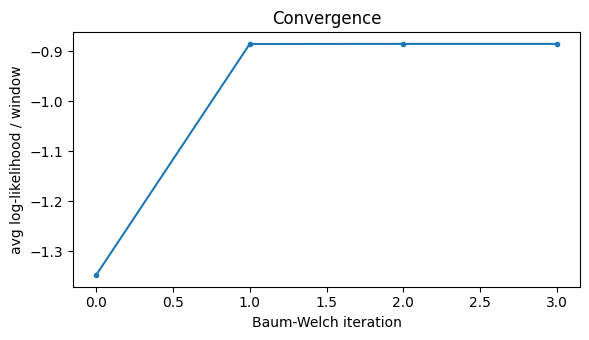

In [12]:
def stitch(recs, n_seq, lo=3, hi=6):
    seqs, labs = [], []
    for _ in range(n_seq):
        pick = [recs[i] for i in RNG.integers(0, len(recs), size=RNG.integers(lo, hi + 1))]
        seqs.append(np.vstack([r["X"] for r in pick])); labs.append(np.concatenate([r["y"] for r in pick]))
    return seqs, labs

train_seqs, train_labs = stitch(train_recs, n_seq=100)
D = train_seqs[0].shape[1]

hmm_sup = GaussianHMM(K, D).init_from_labels(train_seqs, train_labs)

hmm = GaussianHMM(K, D).init_from_labels(train_seqs, train_labs)
ll_hist = hmm.fit(train_seqs, max_iter=200, tol=1e-4)

pred_tr = np.concatenate([hmm.viterbi(X)[0] for X in train_seqs])
cm_tr = confusion(np.concatenate(train_labs), pred_tr)
row, col = linear_sum_assignment(-cm_tr)
hmm.permute(col[np.argsort(row)])
print("state permutation applied:", col[np.argsort(row)])

plt.figure(figsize=(6, 3.5)); plt.plot(ll_hist, marker="o", ms=3)
plt.xlabel("Baum-Welch iteration"); plt.ylabel("avg log-likelihood / window"); plt.title("Convergence")
plt.tight_layout(); plt.savefig("figures/convergence.png", dpi=150); plt.show()


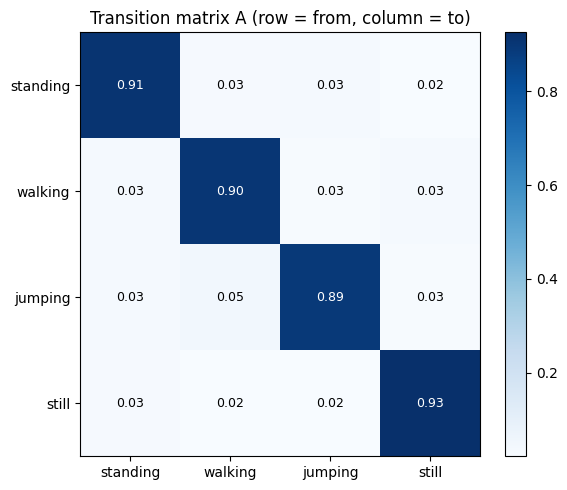

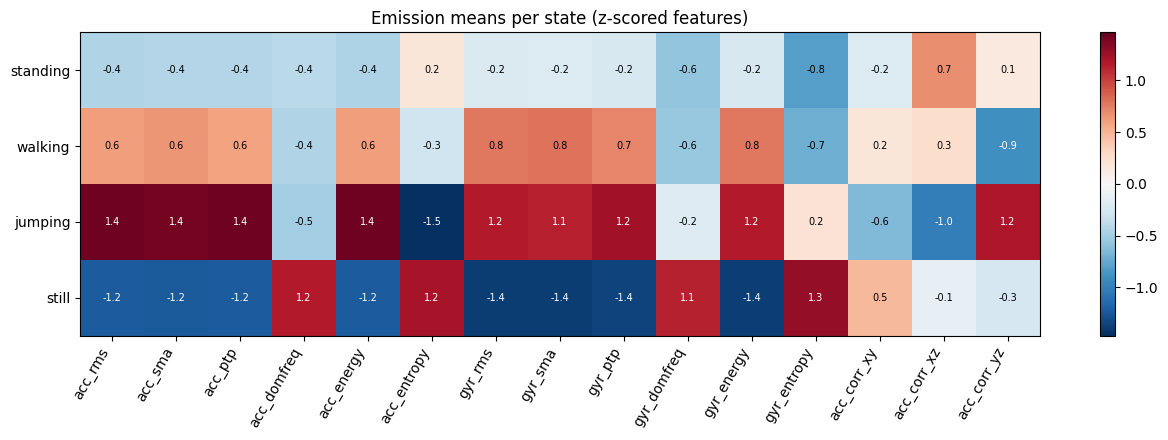

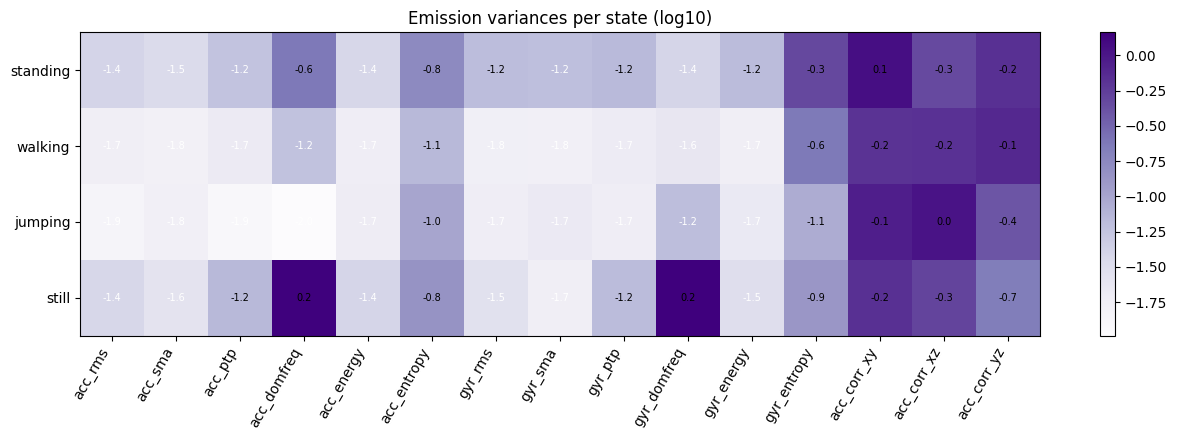

Initial state probabilities pi: {'standing': np.float64(0.29), 'walking': np.float64(0.32), 'jumping': np.float64(0.21), 'still': np.float64(0.18)}


In [13]:
def heatmap(M, xt, yt, title, fname, fmt="{:.2f}", cmap="Blues", size=(6, 5), sym=False, fs=9):
    fig, ax = plt.subplots(figsize=size)
    kw = dict(vmin=-np.abs(M).max(), vmax=np.abs(M).max()) if sym else {}
    im = ax.imshow(M, cmap=cmap, aspect="auto", **kw)
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=60 if len(xt) > 6 else 0, ha="right" if len(xt) > 6 else "center")
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs,
                                 color="white" if abs(v) > 0.6 * np.abs(M).max() else "black")
    plt.colorbar(im, ax=ax); ax.set_title(title); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

heatmap(hmm.A, ACTIVITIES, ACTIVITIES, "Transition matrix A (row = from, column = to)", "figures/transition_matrix.png")
heatmap(hmm.mu, FEATURE_NAMES, ACTIVITIES, "Emission means per state (z-scored features)", "figures/emission_means.png",
        fmt="{:.1f}", cmap="RdBu_r", size=(13, 4.5), sym=True, fs=7)
heatmap(np.log10(hmm.var), FEATURE_NAMES, ACTIVITIES, "Emission variances per state (log10)", "figures/emission_variances.png",
        fmt="{:.1f}", cmap="Purples", size=(13, 4.5), fs=7)
print("Initial state probabilities pi:", dict(zip(ACTIVITIES, hmm.pi.round(3))))

Overall window accuracy on unseen test files
  independent Gaussian classifier (no transitions): 0.978
  HMM, supervised init only (Viterbi):              0.968
  HMM + Baum-Welch (Viterbi):                       0.978

Table for the report (Viterbi, Baum-Welch model):
State (Activity)  Number of Samples  Sensitivity  Specificity  Accuracy
        standing                 23        0.913         1.00     0.978
         walking                 26        1.000         0.97     0.978
         jumping                 20        1.000         1.00     1.000
           still                 24        1.000         1.00     1.000

Overall accuracy: 0.978 on 93 windows from 12 test files


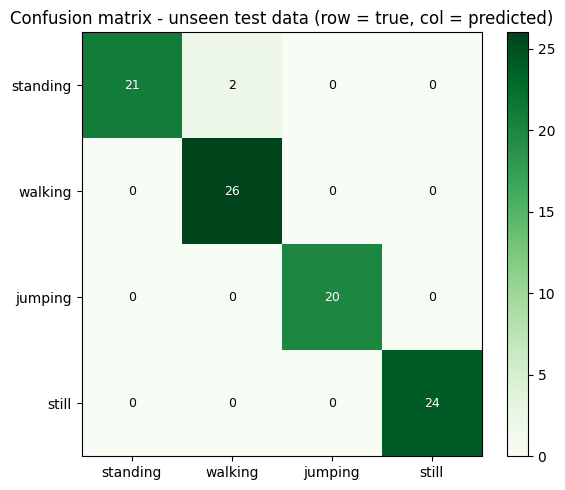

In [14]:
def evaluate(model, recs, name):
    yt = np.concatenate([r["y"] for r in recs])
    yp = np.concatenate([model.viterbi(r["X"])[0] for r in recs])
    return yt, yp, confusion(yt, yp)

yt, yp, cm_te = evaluate(hmm, test_recs, "HMM + Baum-Welch")
_, yp_sup, cm_sup = evaluate(hmm_sup, test_recs, "HMM supervised")
yp_ind = np.concatenate([hmm.log_emission(r["X"]).argmax(1) for r in test_recs])

acc = lambda a, b: (a == b).mean()
print("Overall window accuracy on unseen test files")
print(f"  independent Gaussian classifier (no transitions): {acc(yt, yp_ind):.3f}")
print(f"  HMM, supervised init only (Viterbi):              {acc(yt, yp_sup):.3f}")
print(f"  HMM + Baum-Welch (Viterbi):                       {acc(yt, yp):.3f}")

table = per_class_metrics(cm_te)
table.to_csv("results_table.csv", index=False)
print("\nTable for the report (Viterbi, Baum-Welch model):")
print(table.round(3).to_string(index=False))
print(f"\nOverall accuracy: {np.trace(cm_te)/cm_te.sum():.3f} on {cm_te.sum()} windows from {len(test_recs)} test files")

heatmap(cm_te.astype(float), ACTIVITIES, ACTIVITIES, "Confusion matrix - unseen test data (row = true, col = predicted)",
        "figures/confusion_matrix.png", fmt="{:.0f}", cmap="Greens")


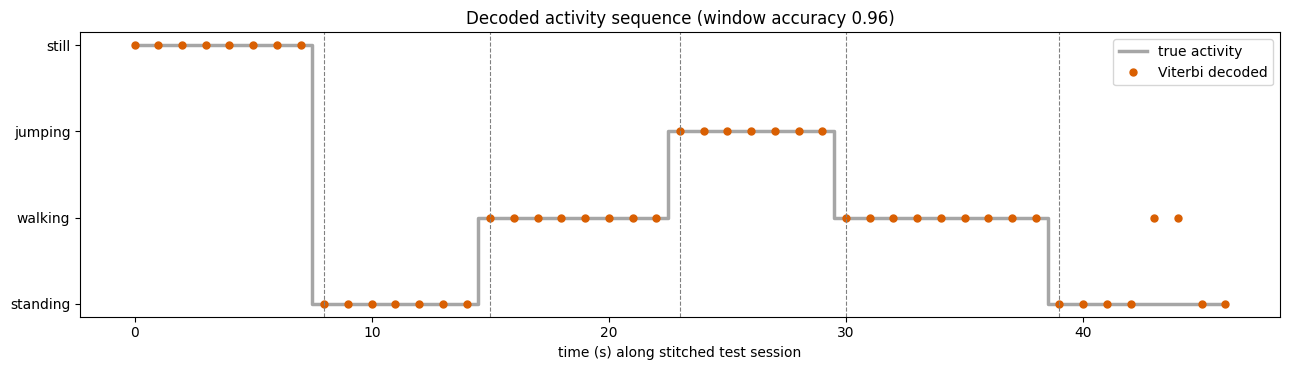

files in this sequence: ['still_p1_01.csv', 'standing_p1_01.csv', 'walking_p1_01.csv', 'jumping_p1_01.csv', 'walking_p1_02.csv', 'standing_p1_02.csv']


In [15]:
order = ["still", "standing", "walking", "jumping", "walking", "standing"]
used, seq_recs = {a: 0 for a in ACTIVITIES}, []
for a in order:
    pool = [r for r in test_recs if r["activity"] == a]
    if pool: seq_recs.append(pool[used[a] % len(pool)]); used[a] += 1

Xs = np.vstack([r["X"] for r in seq_recs]); ys = np.concatenate([r["y"] for r in seq_recs])
path, _ = hmm.viterbi(Xs)
t = np.arange(len(ys)) * (STEP / TARGET_FS)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.step(t, ys, where="mid", color="black", lw=2.5, alpha=0.35, label="true activity")
ax.plot(t, path, "o", ms=5, color="#d95f02", label="Viterbi decoded")
b = np.cumsum([len(r["y"]) for r in seq_recs])[:-1] * (STEP / TARGET_FS)
for x in b: ax.axvline(x, color="grey", ls="--", lw=0.8)
ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_xlabel("time (s) along stitched test session")
ax.set_title(f"Decoded activity sequence (window accuracy {acc(ys, path):.2f})"); ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig("figures/decoded_sequence.png", dpi=150); plt.show()
print("files in this sequence:", [r["file"] for r in seq_recs])

In [16]:
import shutil
shutil.make_archive("results_for_report", "zip", ".", "figures")
print("Saved: dataset_inventory.csv, results_table.csv, results_for_report.zip (figures)")
try:
    from google.colab import files
    for f in ["results_for_report.zip", "results_table.csv", "dataset_inventory.csv"]: files.download(f)
except Exception:
    pass

Saved: dataset_inventory.csv, results_table.csv, results_for_report.zip (figures)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>